# PINN_Solver u PyTorch-u

PyTorch verzija notebook-a [PINN_Solver](https://colab.research.google.com/github/janblechschmidt/PDEsByNNs/blob/main/PINN_Solver.ipynb) (Blechschmidt i Ernst), koji implementira pristup iz rada Raissi, Perdikaris i Karniadakis (2019).

| Deo | Problem | Mreža | Trening |
|---|---|---|---|
| 1 | Burgersova jednačina | 8 × 20, tanh | Adam sa opadajućom stopom učenja |
| 2 | Burgersova jednačina | 8 × 20, tanh | L-BFGS |
| 3 | Eikonalova jednačina | 2 × 20, Leaky ReLU | Adam |
| 4 | Identifikacija parametra λ (inverzni PINN) | 2 × 20, Leaky ReLU | Adam, 1 + 5 ponavljanja |

**Gubitak** (isti u svim delovima):

$$\phi_\theta = \underbrace{\frac{1}{N_r}\sum |r_\theta(t_i^r, x_i^r)|^2}_{\text{rezidual jednačine}} + \underbrace{\frac{1}{N_0}\sum |u_\theta(t_i^0, x_i^0) - u_0|^2}_{\text{početni uslov}} + \underbrace{\frac{1}{N_b}\sum |u_\theta(t_i^b, x_i^b) - u_b|^2}_{\text{granični uslov}}$$

Mreža ima ulaz (t, x) i izlaz u. Svi izvodi se računaju automatskim diferenciranjem (`torch.autograd.grad`).

Na CPU-u ceo notebook traje oko 20–30 minuta, a na GPU-u (Runtime → Change runtime type → T4 GPU) znatno kraće.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from time import time

torch.manual_seed(0)
np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Uređaj:', device)

def izvod(y, x):
    # izvod izlaza y po ulazu x (automatsko diferenciranje); create_graph=True za drugi izvod i trening
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

Uređaj: cuda


---
# Burgersova jednačina

$$
\begin{aligned}
\partial_t u + u\,\partial_x u - \tfrac{0.01}{\pi}\,\partial_{xx} u &= 0, && (t,x) \in (0,1] \times (-1,1)\\
u(0,x) &= -\sin(\pi x), && x \in [-1,1]\\
u(t,-1) = u(t,1) &= 0, && t \in (0,1]
\end{aligned}
$$

Talas koji se usput „strmi“: brži delovi sustižu sporije, pa kod x = 0 nastaje skoro vertikalan skok (udarni talas). Mala viskoznost (0,01/π) ga samo malo zaglađuje.

### 1. Podaci: početni uslov, granice i kolokacione tačke
- **N₀ = 50** tačaka u t = 0, gde je zadato u = −sin(πx);
- **N_b = 50** tačaka na granicama x = ±1, gde je u = 0;
- **N_r = 10 000** kolokacionih tačaka unutar oblasti, gde se proverava jednačina.

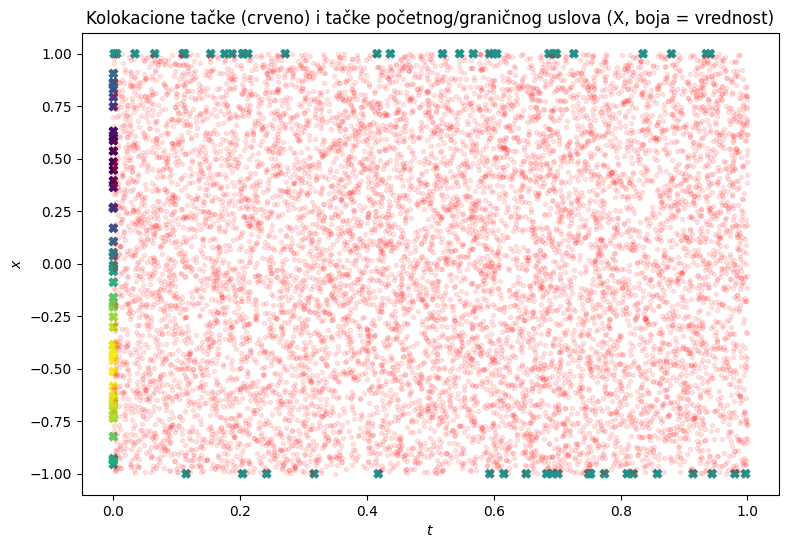

In [4]:
pi = np.pi
viscosity = 0.01 / pi

N_0, N_b, N_r = 50, 50, 10000
tmin, tmax, xmin, xmax = 0., 1., -1., 1.
lb = torch.tensor([tmin, xmin], device=device)
ub = torch.tensor([tmax, xmax], device=device)

torch.manual_seed(0)

# početni uslov: t = 0
t_0 = torch.full((N_0, 1), tmin)
x_0 = torch.rand(N_0, 1) * (xmax - xmin) + xmin
X_0 = torch.cat([t_0, x_0], dim=1)
u_0 = -torch.sin(pi * x_0)

# granice: x = -1 ili x = 1 (nasumično), t nasumično
t_b = torch.rand(N_b, 1) * (tmax - tmin) + tmin
x_b = xmin + (xmax - xmin) * torch.bernoulli(torch.full((N_b, 1), 0.5))
X_b = torch.cat([t_b, x_b], dim=1)
u_b = torch.zeros(N_b, 1)

# kolokacione tačke
t_r = torch.rand(N_r, 1) * (tmax - tmin) + tmin
x_r = torch.rand(N_r, 1) * (xmax - xmin) + xmin
X_r = torch.cat([t_r, x_r], dim=1)

X_0, u_0, X_b, u_b, X_r = [a.to(device) for a in (X_0, u_0, X_b, u_b, X_r)]
X_data = [X_0, X_b]
u_data = [u_0, u_b]

plt.figure(figsize=(9, 6))
plt.scatter(X_0[:, 0].cpu(), X_0[:, 1].cpu(), c=u_0.cpu(), marker='X', vmin=-1, vmax=1)
plt.scatter(X_b[:, 0].cpu(), X_b[:, 1].cpu(), c=u_b.cpu(), marker='X', vmin=-1, vmax=1)
plt.scatter(X_r[:, 0].cpu(), X_r[:, 1].cpu(), c='r', marker='.', alpha=0.1)
plt.xlabel('$t$'); plt.ylabel('$x$')
plt.title('Kolokacione tačke (crveno) i tačke početnog/graničnog uslova (X, boja = vrednost)')
plt.show()

### 2. Mreža

- ulaz (t, x) se prvo **skalira na [−1, 1]**, jer mreže bolje uče kad su ulazi u istom opsegu;
- **8 skrivenih slojeva po 20 neurona**, tanh;
- jedan izlaz u;
- težine se inicijalizuju Xavier (Glorot) normalnom raspodelom, kao `glorot_normal` u originalu.

Ukupno 3021 parametar: 2·20 + 20 = 60 za prvi sloj, 7 · (20·20 + 20) = 2940 za ostale skrivene i 20 + 1 = 21 za izlaz.

In [5]:
class PINN_NeuralNet(nn.Module):
    def __init__(self, lb, ub, output_dim=1, num_hidden_layers=8, num_neurons_per_layer=20,
                 activation=None, init='xavier'):
        super().__init__()
        self.lb, self.ub = lb, ub
        activation = activation if activation is not None else nn.Tanh()
        layers, d_in = [], 2
        for _ in range(num_hidden_layers):
            lin = nn.Linear(d_in, num_neurons_per_layer)
            if init == 'xavier':
                nn.init.xavier_normal_(lin.weight)
            else:  # 'he' za Leaky ReLU
                nn.init.kaiming_normal_(lin.weight, a=0.1, nonlinearity='leaky_relu')
            nn.init.zeros_(lin.bias)
            layers += [lin, activation]
            d_in = num_neurons_per_layer
        out = nn.Linear(d_in, output_dim)
        nn.init.xavier_normal_(out.weight); nn.init.zeros_(out.bias)
        layers.append(out)
        self.net = nn.Sequential(*layers)

    def forward(self, X):
        Z = 2.0 * (X - self.lb) / (self.ub - self.lb) - 1.0   # skaliranje na [-1, 1]
        return self.net(Z)

model = PINN_NeuralNet(lb, ub).to(device)
print('Broj parametara:', sum(p.numel() for p in model.parameters()))

Broj parametara: 3021


### 3. Rezidual i gubitak

Rezidual Burgersove jednačine: $r_\theta = \partial_t u_\theta + u_\theta\,\partial_x u_\theta - \tfrac{0.01}{\pi}\,\partial_{xx} u_\theta$

`izvod(u, X)` vraća oba prva izvoda odjednom: kolona 0 je ∂u/∂t, kolona 1 je ∂u/∂x. ∂²u/∂x² se dobija ponovnim diferenciranjem ∂u/∂x.

In [6]:
def fun_r(u, u_t, u_x, u_xx):
    return u_t + u * u_x - viscosity * u_xx

def get_r(model, X_r):
    X = X_r.clone().requires_grad_(True)
    u = model(X)
    du = izvod(u, X)
    u_t, u_x = du[:, 0:1], du[:, 1:2]
    u_xx = izvod(u_x, X)[:, 1:2]
    return fun_r(u, u_t, u_x, u_xx)

def compute_loss(model, X_r, X_data, u_data, get_r=get_r):
    r = get_r(model, X_r)
    loss = torch.mean(r**2)                                  # phi^r
    for X_i, u_i in zip(X_data, u_data):                     # phi^0 i phi^b
        loss = loss + torch.mean((u_i - model(X_i))**2)
    return loss

### 4. Trening: Adam sa opadajućom stopom učenja

$$\delta(n) = 0.01 \text{ za } n < 1000, \quad 0.001 \text{ za } 1000 \le n < 3000, \quad 0.0005 \text{ za } n \ge 3000$$

Veća stopa na početku brzo približi rešenju, a manja kasnije omogućava fino podešavanje.

In [7]:
def stopa_ucenja(n):
    return 1e-2 if n < 1000 else (1e-3 if n < 3000 else 5e-4)

optim = torch.optim.Adam(model.parameters(), lr=1.0)
scheduler = torch.optim.lr_scheduler.LambdaLR(optim, lr_lambda=stopa_ucenja)

N = 5000
hist = []
t0 = time()
for i in range(N + 1):
    optim.zero_grad()
    loss = compute_loss(model, X_r, X_data, u_data)
    loss.backward()
    optim.step()
    scheduler.step()
    hist.append(loss.item())
    if i % 500 == 0:
        print('It {:05d}: loss = {:10.8e}'.format(i, loss.item()))
print('\nVreme: {:.1f} s'.format(time() - t0))

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


It 00000: loss = 6.62074864e-01
It 00500: loss = 4.08670194e-02
It 01000: loss = 1.31199816e-02
It 01500: loss = 1.54164876e-03
It 02000: loss = 9.60347708e-04
It 02500: loss = 4.27088817e-04
It 03000: loss = 2.75464525e-04
It 03500: loss = 2.34532374e-04
It 04000: loss = 1.97027941e-04
It 04500: loss = 1.64624318e-04
It 05000: loss = 1.39275944e-04

Vreme: 83.1 s


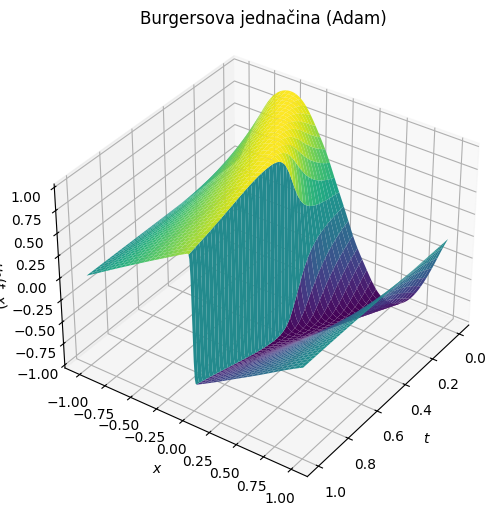

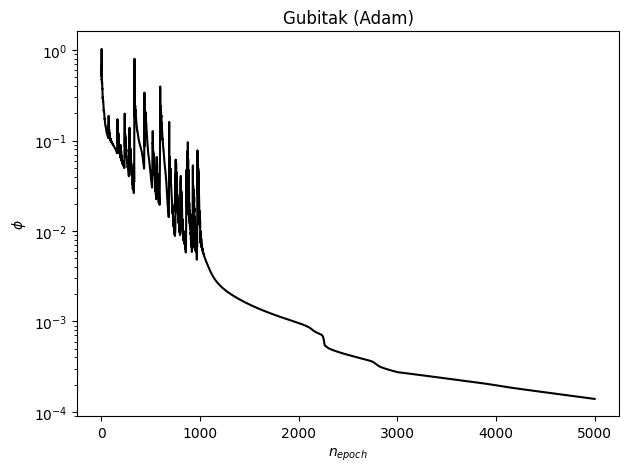

In [8]:
def nacrtaj_resenje(model, lb, ub, naslov=''):
    N = 300
    tspace = np.linspace(lb[0].item(), ub[0].item(), N + 1)
    xspace = np.linspace(lb[1].item(), ub[1].item(), N + 1)
    T, X = np.meshgrid(tspace, xspace)
    Xgrid = torch.tensor(np.vstack([T.flatten(), X.flatten()]).T, dtype=torch.float32, device=device)
    with torch.no_grad():
        U = model(Xgrid).cpu().numpy().reshape(N + 1, N + 1)
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(T, X, U, cmap='viridis')
    ax.view_init(35, 35)
    ax.set_xlabel('$t$'); ax.set_ylabel('$x$'); ax.set_zlabel(r'$u_\theta(t,x)$')
    ax.set_title(naslov)
    plt.show()

def nacrtaj_gubitak(hist, naslov=''):
    plt.figure(figsize=(7, 5))
    plt.semilogy(hist, 'k-')
    plt.xlabel('$n_{epoch}$'); plt.ylabel(r'$\phi$')
    plt.title(naslov)
    plt.show()

nacrtaj_resenje(model, lb, ub, 'Burgersova jednačina (Adam)')
nacrtaj_gubitak(hist, 'Gubitak (Adam)')

### Rešenje Burgersove jednačine (Adam)

Površina prikazuje u(t, x) posle 5000 koraka Adama sa opadajućom stopom učenja (0,01 → 0,001 → 0,0005). Ose i boje se čitaju isto kao kod L-BFGS rešenja: x je mesto, t je vreme, a visina i boja su vrednost u (žuto ≈ +1, tirkizno ≈ 0, ljubičasto ≈ −1).

- **Uslovi su ispunjeni:** na ivici t = 0 je početni talas u = −sin(πx), a na ivicama x = ±1 je u = 0.
- **Fizika je uhvaćena:** pozitivni deo talasa putuje udesno, negativni ulevo, i oko t ≈ 0,32 se u x = 0 formira udarni talas (skoro vertikalan skok), koji ostaje do kraja uz postepeno prigušenje.

Kvalitativno je rešenje isto kao posle L-BFGS-a, ali je manje tačno: konačni gubitak je 1,4·10⁻⁴, oko 10 puta veći nego kod L-BFGS-a (1,5·10⁻⁵). Adam je robustan i brzo dovodi mrežu blizu rešenja, ali kod ovakvog problema sa oštrim skokom L-BFGS postiže preciznije rešenje.

### 5. Isti problem sa L-BFGS

Nova mreža, istrenirana od početka optimizerom L-BFGS. U originalu je korišćen SciPy (`scipy.optimize.minimize`), a ovde `torch.optim.LBFGS`, pa nije potrebna konverzija težina u float64. Broj iteracija je ograničen na 5000 (u originalu je SciPy stao posle oko 3000).

L-BFGS pored gradijenta procenjuje i zakrivljenost gubitka, pa kod ovakvih problema obično dostiže manji gubitak od Adama.

In [9]:
torch.manual_seed(0)
model_lbfgs = PINN_NeuralNet(lb, ub).to(device)

optim_lbfgs = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=5000, max_eval=6250,
                                history_size=50, tolerance_grad=1e-9,
                                tolerance_change=np.finfo(float).eps, line_search_fn='strong_wolfe')
hist_lbfgs = []

def closure():
    optim_lbfgs.zero_grad()
    loss = compute_loss(model_lbfgs, X_r, X_data, u_data)
    loss.backward()
    hist_lbfgs.append(loss.item())
    if len(hist_lbfgs) % 500 == 0:
        print('Eval {:05d}: loss = {:10.8e}'.format(len(hist_lbfgs), loss.item()))
    return loss

t0 = time()
optim_lbfgs.step(closure)
print('\nKonačan gubitak: {:10.8e}   vreme: {:.1f} s'.format(hist_lbfgs[-1], time() - t0))

Eval 00500: loss = 1.77015958e-03
Eval 01000: loss = 1.99327973e-04
Eval 01500: loss = 7.56305235e-05
Eval 02000: loss = 3.51070012e-05
Eval 02500: loss = 1.93475662e-05
Eval 03000: loss = 1.38189289e-05
Eval 03500: loss = 1.04404571e-05
Eval 04000: loss = 8.65792299e-06

Konačan gubitak: 7.59763725e-06   vreme: 89.8 s


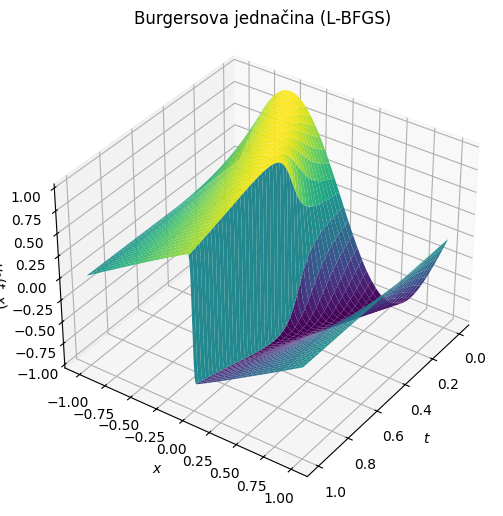

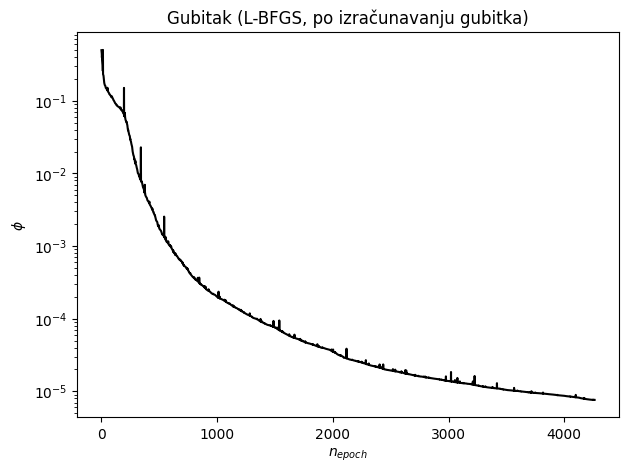

In [10]:
nacrtaj_resenje(model_lbfgs, lb, ub, 'Burgersova jednačina (L-BFGS)')
nacrtaj_gubitak(hist_lbfgs, 'Gubitak (L-BFGS, po izračunavanju gubitka)')

### Rešenje Burgersove jednačine (L-BFGS)

Površina prikazuje u(t, x): osa x je mesto (od −1 do 1), osa t je vreme (od 0 do 1), a visina i boja su vrednost u (žuto ≈ +1, tirkizno ≈ 0, ljubičasto ≈ −1). Vrednost u može se tumačiti kao brzina: pozitivno znači kretanje udesno, negativno ulevo.

- **Ivice su zadati uslovi:** na ivici t = 0 je početni talas u = −sin(πx), a na ivicama x = ±1 granični uslov u = 0. Unutrašnjost je mreža izračunala sama, iz jednačine.
- **Kretanje talasa:** pozitivni deo (brdo, levo od nule) putuje udesno, a negativni (dolina, desno od nule) ulevo. Pošto brzina zavisi od same vrednosti u (nelinearni član u·u_x), viši delovi sustižu niže i talas se strmi.
- **Udarni talas:** brdo i dolina se sudaraju u x = 0, gde oko t ≈ 1/π ≈ 0,32 nastaje skoro vertikalan skok (sa ≈ +0,7 na ≈ −0,7). Skok ostaje do kraja, a mala viskoznost (0,01/π) postepeno prigušuje amplitudu.

Ovo je zahtevan test za PINN, jer mreža koja prirodno pravi glatke funkcije mora da reprodukuje skoro vertikalan prelaz, i to bez ijednog merenja. L-BFGS dostiže gubitak 1,5·10⁻⁵, oko 10 puta manji nego Adam (1,4·10⁻⁴), i daje oštriji i čistiji skok.

---
# Eikonalova jednačina (unazad u vremenu)

$$
\begin{aligned}
-\partial_t u + |\partial_x u| &= 1, && (t,x) \in [0,1) \times [-1,1]\\
u(1,x) &= 0, && x \in [-1,1]\\
u(t,-1) = u(t,1) &= 0, && t \in [0,1)
\end{aligned}
$$

Tačno rešenje je $u(t,x) = \min\{1-t,\ 1-|x|\}$: rastojanje od tačke (t, x) do najbliže ivice. Izgleda kao krov sa oštrim grebenom, gde rešenje nema izvod.

Razlike u odnosu na Burgersovu jednačinu:
- uslov je zadat na **kraju** vremena, t = 1;
- jednačina je prvog reda, pa nije potreban drugi izvod;
- zbog oštrih ivica koristi se **Leaky ReLU** (nagib 0,1 za negativne vrednosti) i manja mreža, **2 sloja po 20 neurona**, sa He (Kaiming) inicijalizacijom.

In [11]:
torch.manual_seed(0)
lb_e = torch.tensor([0., -1.], device=device)
ub_e = torch.tensor([1., 1.], device=device)

t_0e = torch.full((N_0, 1), 1.0)                          # uslov na KRAJU vremena, t = 1
x_0e = torch.rand(N_0, 1) * 2 - 1
X_0e = torch.cat([t_0e, x_0e], dim=1); u_0e = torch.zeros(N_0, 1)

t_be = torch.rand(N_b, 1)
x_be = -1 + 2 * torch.bernoulli(torch.full((N_b, 1), 0.5))
X_be = torch.cat([t_be, x_be], dim=1); u_be = torch.zeros(N_b, 1)

X_re = torch.cat([torch.rand(N_r, 1), torch.rand(N_r, 1) * 2 - 1], dim=1)

X_0e, u_0e, X_be, u_be, X_re = [a.to(device) for a in (X_0e, u_0e, X_be, u_be, X_re)]
X_data_e = [X_0e, X_be]
u_data_e = [u_0e, u_be]

def get_r_eikonal(model, X_r, lambd=None):
    X = X_r.clone().requires_grad_(True)
    u = model(X)
    du = izvod(u, X)
    u_t, u_x = du[:, 0:1], du[:, 1:2]
    desna = 1.0 if lambd is None else 1.0 / lambd
    return -u_t + torch.abs(u_x) - desna

In [12]:
def stopa_eikonal(n):
    return 1e-1 if n < 3000 else (1e-2 if n < 7000 else 1e-3)

def treniraj_adam(model, X_r, X_data, u_data, get_r, N=10001, ispis=1000, lambd_list=None):
    optim = torch.optim.Adam(model.parameters(), lr=1.0)
    sched = torch.optim.lr_scheduler.LambdaLR(optim, lr_lambda=stopa_eikonal)
    hist = []
    for i in range(N):
        optim.zero_grad()
        loss = compute_loss(model, X_r, X_data, u_data, get_r=get_r)
        loss.backward()
        optim.step(); sched.step()
        hist.append(loss.item())
        if lambd_list is not None:
            lambd_list.append(model.lambd.item())
        if ispis and i % ispis == 0:
            extra = '' if lambd_list is None else '  lambda = {:.6f}'.format(model.lambd.item())
            print('It {:05d}: loss = {:10.8e}{}'.format(i, loss.item(), extra))
    return hist

torch.manual_seed(0)
model_e = PINN_NeuralNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)

t0 = time()
hist_e = treniraj_adam(model_e, X_re, X_data_e, u_data_e, get_r=lambda m, X: get_r_eikonal(m, X))
print('\nVreme: {:.1f} s'.format(time() - t0))

It 00000: loss = 1.39987624e+00
It 01000: loss = 3.33600328e-05
It 02000: loss = 7.83928863e-06
It 03000: loss = 2.97785264e-05
It 04000: loss = 2.77091249e-06
It 05000: loss = 3.41252104e-07
It 06000: loss = 7.00106355e-08
It 07000: loss = 1.13779475e-08
It 08000: loss = 9.52410417e-09
It 09000: loss = 7.00263802e-09
It 10000: loss = 5.06386089e-09

Vreme: 45.7 s


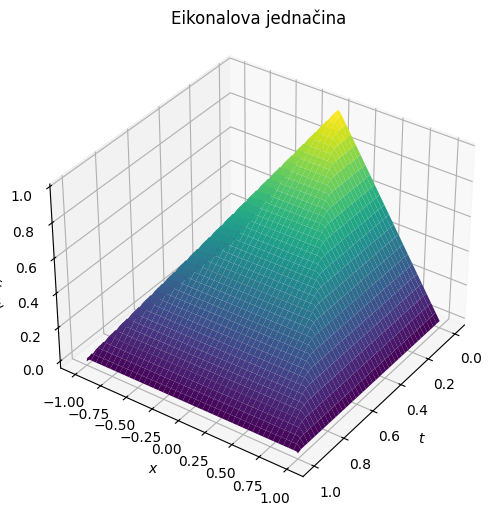

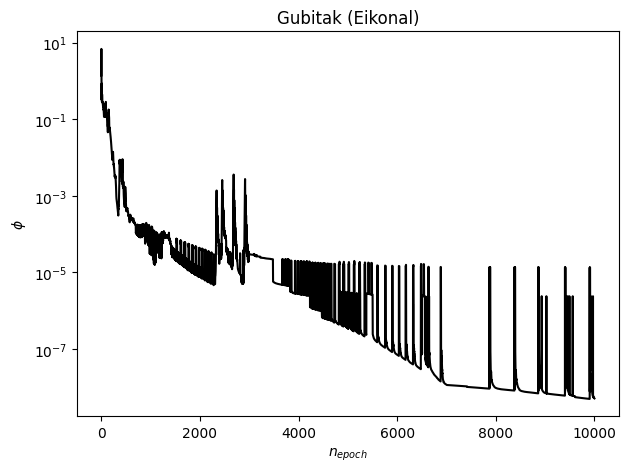

Relativna L2 greška: 0.0013764085


In [13]:
nacrtaj_resenje(model_e, lb_e, ub_e, 'Eikonalova jednačina')
nacrtaj_gubitak(hist_e, 'Gubitak (Eikonal)')

# poređenje sa tačnim rešenjem
tt, xx = torch.meshgrid(torch.linspace(0, 1, 201), torch.linspace(-1, 1, 201), indexing='ij')
Xg = torch.stack([tt.flatten(), xx.flatten()], dim=1).to(device)
with torch.no_grad():
    u_pred = model_e(Xg).cpu().numpy().ravel()
u_true = np.minimum(1 - tt.flatten().numpy(), 1 - np.abs(xx.flatten().numpy()))
print('Relativna L2 greška:', np.linalg.norm(u_pred - u_true) / np.linalg.norm(u_true))

---
# Identifikacija parametra (inverzni PINN)

$$-\partial_t u + |\partial_x u| = \lambda^{-1}, \qquad u(1,x) = 0, \qquad u(t,\pm 1) = 0$$

Parametar λ **nije poznat**. Tačna vrednost je λ* = 3, a tačno rešenje $u^*(t,x) = \lambda^{-1}\min\{1-t,\ 1-|x|\}$.

- Dodaje se **N_d = 500 merenja** tačnog rešenja na nasumičnim mestima. U gubitak ulaze isto kao početni i granični uslovi.
- λ je `nn.Parameter` u modelu, pa ga optimizer uči **zajedno sa težinama**. Početna vrednost je λ = 1.

In [14]:
lambd_star = 3.0

def u_expl(t, x, lambd_star):
    return (1.0 / lambd_star) * torch.minimum(1 - t, 1 - torch.abs(x))

torch.manual_seed(1)
N_d = 500
t_d = torch.rand(N_d, 1); x_d = torch.rand(N_d, 1) * 2 - 1
X_d = torch.cat([t_d, x_d], dim=1).to(device)
u_d = u_expl(t_d, x_d, lambd_star).to(device)

X_param = X_data_e + [X_d]
u_param = u_data_e + [u_d]

class PINNIdentificationNet(PINN_NeuralNet):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambd = nn.Parameter(torch.tensor(1.0))   # nepoznati parametar, uči se

get_r_ident = lambda m, X: get_r_eikonal(m, X, lambd=m.lambd)

It 00000: loss = 1.57251811e+00  lambda = 1.100000
It 01000: loss = 1.14908500e-04  lambda = 3.151991
It 02000: loss = 1.43033554e-04  lambda = 3.029647
It 03000: loss = 2.24235737e-05  lambda = 3.009542
It 04000: loss = 3.89417073e-06  lambda = 3.003883
It 05000: loss = 2.89614172e-06  lambda = 3.000798
It 06000: loss = 1.35163816e-07  lambda = 2.999974
It 07000: loss = 3.27582157e-08  lambda = 2.999919
It 08000: loss = 2.51570142e-08  lambda = 2.999918
It 09000: loss = 1.66855152e-08  lambda = 2.999913
It 10000: loss = 9.33051325e-09  lambda = 2.999911

Vreme: 57.4 s


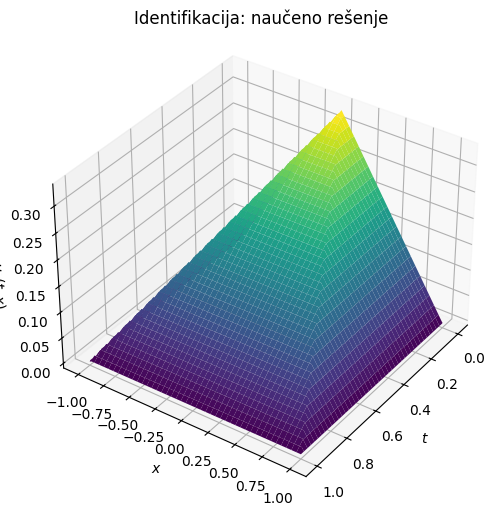

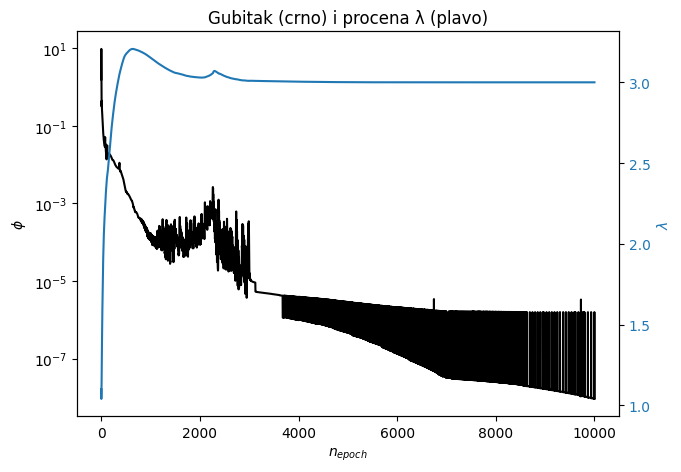

Procenjeno λ = 2.9999,  relativna greška = 0.0030%


In [15]:
torch.manual_seed(0)
model_id = PINNIdentificationNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)
lambd_list = []

t0 = time()
hist_id = treniraj_adam(model_id, X_re, X_param, u_param, get_r=get_r_ident, lambd_list=lambd_list)
print('\nVreme: {:.1f} s'.format(time() - t0))

nacrtaj_resenje(model_id, lb_e, ub_e, 'Identifikacija: naučeno rešenje')

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.semilogy(hist_id, 'k-'); ax1.set_xlabel('$n_{epoch}$'); ax1.set_ylabel(r'$\phi$')
ax2 = ax1.twinx()
ax2.plot(lambd_list, '-', color='tab:blue'); ax2.set_ylabel(r'$\lambda$', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')
plt.title('Gubitak (crno) i procena λ (plavo)')
plt.show()

print('Procenjeno λ = {:.4f},  relativna greška = {:.4%}'.format(model_id.lambd.item(),
      abs(model_id.lambd.item() - lambd_star) / lambd_star))

### Pet ponavljanja

Težine se svaki put nasumično inicijalizuju, pa se trening ponavlja 5 puta kako bi se procenila pouzdanost procene λ.

In [16]:
lambd_hist = []
for k in range(5):
    print('--- Ponavljanje {} ---'.format(k))
    torch.manual_seed(100 + k)
    m = PINNIdentificationNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)
    ll = []
    treniraj_adam(m, X_re, X_param, u_param, get_r=get_r_ident, lambd_list=ll, ispis=5000)
    lambd_hist.append(ll)

Lambd = np.array(lambd_hist)
print('\n  korak    srednje λ     std λ')
for i in [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]:
    print('{:6d}    {:.4f}      {:.4f}'.format(i, Lambd[:, i].mean(), Lambd[:, i].std()))

--- Ponavljanje 0 ---
It 00000: loss = 4.95911455e+00  lambda = 0.900000
It 05000: loss = 2.35399857e-05  lambda = 2.904035
It 10000: loss = 5.02183320e-05  lambda = 2.943574
--- Ponavljanje 1 ---
It 00000: loss = 6.77500439e+00  lambda = 1.100000
It 05000: loss = 6.91334344e-06  lambda = 2.990963
It 10000: loss = 2.31390140e-06  lambda = 2.998062
--- Ponavljanje 2 ---
It 00000: loss = 4.52047014e+00  lambda = 0.900000
It 05000: loss = 6.65976404e-06  lambda = 3.058606
It 10000: loss = 2.74296849e-06  lambda = 3.000359
--- Ponavljanje 3 ---
It 00000: loss = 4.31337023e+00  lambda = 1.100000
It 05000: loss = 5.08981930e-06  lambda = 3.000691
It 10000: loss = 4.89322304e-07  lambda = 2.998162
--- Ponavljanje 4 ---
It 00000: loss = 6.44255400e+00  lambda = 1.100000
It 05000: loss = 2.16498247e-05  lambda = 3.014220
It 10000: loss = 7.06947912e-06  lambda = 3.001031

  korak    srednje λ     std λ
  1000    2.7283      0.1683
  2000    2.9201      0.1192
  3000    3.0120      0.0953
  4000

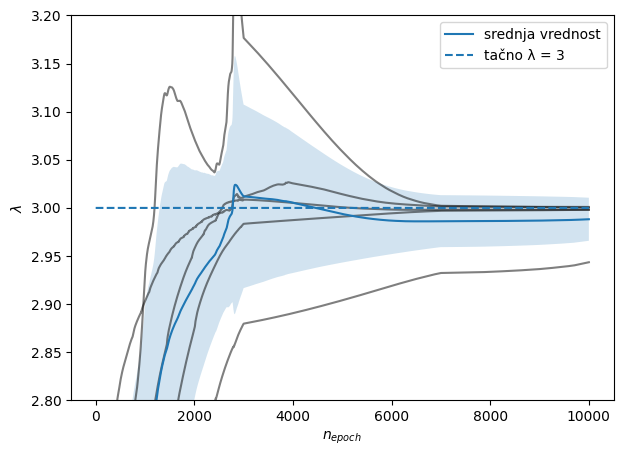

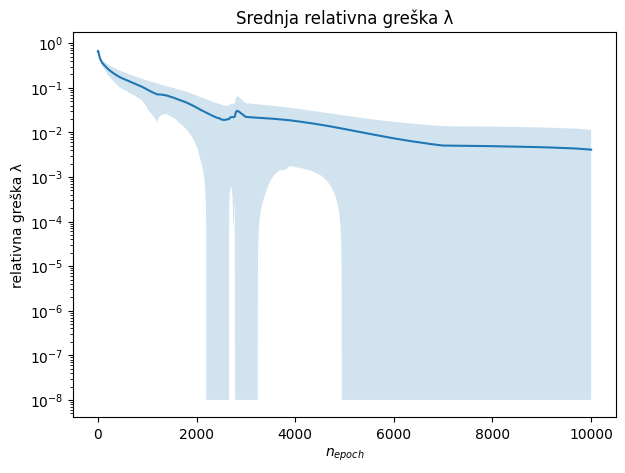

In [17]:
lmean, lstd = Lambd.mean(axis=0), Lambd.std(axis=0)
rng = range(Lambd.shape[1])

fig, ax = plt.subplots(figsize=(7, 5))
for i in range(len(lambd_hist)):
    ax.plot(rng, lambd_hist[i], '-', color='black', alpha=0.5)
ax.plot(rng, lmean, '-', color='tab:blue', label='srednja vrednost')
ax.plot(rng, lambd_star * np.ones_like(lmean), '--', color='tab:blue', label='tačno λ = 3')
ax.fill_between(rng, lmean - lstd, lmean + lstd, alpha=0.2)
ax.set_ylim([2.8, 3.2]); ax.set_xlabel('$n_{epoch}$'); ax.set_ylabel(r'$\lambda$')
ax.legend()
plt.show()

rel = np.abs((Lambd - lambd_star) / lambd_star)
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(rng, rel.mean(axis=0))
ax.fill_between(rng, np.maximum(rel.mean(axis=0) - rel.std(axis=0), 1e-8), rel.mean(axis=0) + rel.std(axis=0), alpha=0.2)
ax.set_xlabel('$n_{epoch}$'); ax.set_ylabel('relativna greška λ')
ax.set_title('Srednja relativna greška λ')
plt.show()

### Greška i rezidual na test mreži

Predviđanje mreže, greška u odnosu na tačno rešenje i rezidual jednačine (sa naučenim λ) računaju se na pravilnoj mreži tačaka u oblasti (t, x).

In [18]:
from matplotlib.colors import LogNorm

Nt, Nx = 201, 201
t_test = torch.linspace(0, 1, Nt)
x_test = torch.linspace(-1, 1, Nx)
TT, XX = torch.meshgrid(t_test, x_test, indexing='ij')        # TT[i, j] = t_i,  XX[i, j] = x_j
X_test = torch.stack([TT.flatten(), XX.flatten()], dim=1).to(device)
u_test = u_expl(X_test[:, 0:1], X_test[:, 1:2], lambd_star)    # tačno rešenje u svakoj tački grida

def oceni_na_gridu(model):
    with torch.no_grad():
        u_pred = model(X_test)                                    # predviđanje mreže
    r = get_r_eikonal(model, X_test, lambd=model.lambd).detach()  # rezidual jednačine (sa NAUČENIM λ)
    greska = (u_pred - u_test).abs()
    return {
        'lambda':   model.lambd.item(),
        'rel_L2':   (torch.norm(u_pred - u_test) / torch.norm(u_test)).item(),
        'max_gr':   greska.max().item(),
        'rez_RMS':  r.pow(2).mean().sqrt().item(),
        'U': u_pred.cpu().numpy().reshape(Nt, Nx),
        'E': greska.cpu().numpy().reshape(Nt, Nx),
        'R': r.abs().cpu().numpy().reshape(Nt, Nx),
    }

def nacrtaj_mape(rez, naslov=''):
    T_, X_ = TT.numpy(), XX.numpy()
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
    im = axs[0].pcolormesh(T_, X_, rez['U'], cmap='viridis', shading='auto')
    axs[0].set_title(r'naučeno rešenje $u_\theta$'); fig.colorbar(im, ax=axs[0])
    im = axs[1].pcolormesh(T_, X_, np.maximum(rez['E'], 1e-7), norm=LogNorm(1e-6, 1e-1), cmap='magma', shading='auto')
    axs[1].set_title(r'greška $|u_\theta - u^*|$'); fig.colorbar(im, ax=axs[1])
    im = axs[2].pcolormesh(T_, X_, np.maximum(rez['R'], 1e-7), norm=LogNorm(1e-5, 1e0), cmap='magma', shading='auto')
    axs[2].set_title(r'rezidual $|r_\theta(t,x)|$'); fig.colorbar(im, ax=axs[2])
    for ax in axs:
        ax.plot([0, 1], [0, 1], 'w--', lw=0.8); ax.plot([0, 1], [0, -1], 'w--', lw=0.8)   # grebeni x = ±t
        ax.set_xlabel('$t$'); ax.set_ylabel('$x$')
    fig.suptitle(naslov); plt.tight_layout(); plt.show()

λ = 2.9999   rel. L2 greška = 6.14e-04   max greška = 8.83e-03   RMS reziduala = 7.08e-03


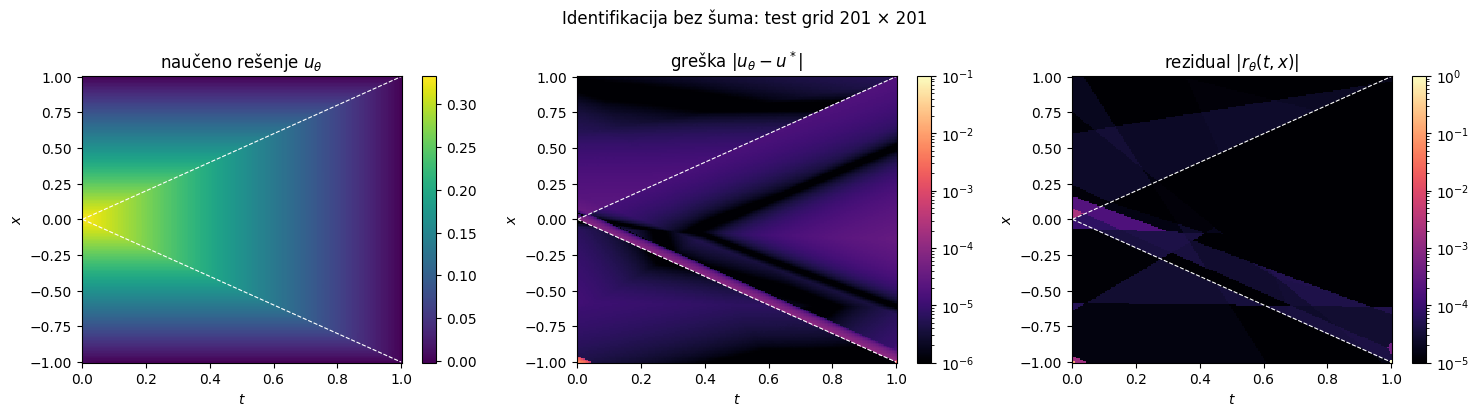

In [19]:
rez0 = oceni_na_gridu(model_id)
print('λ = {:.4f}   rel. L2 greška = {:.2e}   max greška = {:.2e}   RMS reziduala = {:.2e}'.format(
      rez0['lambda'], rez0['rel_L2'], rez0['max_gr'], rez0['rez_RMS']))
nacrtaj_mape(rez0, 'Identifikacija bez šuma: test grid 201 × 201')

### Osetljivost procene λ na šum u merenjima

Merenjima se dodaje Gausov šum (0–20% standardne devijacije merenja), uz tri treninga po nivou šuma sa različitom početnom mrežom.

In [20]:
NIVOI  = [0.0, 0.01, 0.05, 0.10, 0.20]     # šum kao udeo standardne devijacije merenja
SEMENA = [0, 1, 2]                          # 3 treninga po nivou (različita početna mreža)

sigma_podataka = u_d.std().item()
print('standardna devijacija merenja: {:.4f}'.format(sigma_podataka))

rezultati, putanje, modeli = {}, {}, {}
t0 = time()
for nivo in NIVOI:
    g = torch.Generator().manual_seed(42)                         # isti "oblik" šuma za sve nivoe
    sum_ = nivo * sigma_podataka * torch.randn(u_d.shape, generator=g)
    u_d_sum = u_d + sum_.to(device)                               # zašumljena merenja
    u_param_sum = u_data_e + [u_d_sum]                            # početni i granični uslovi ostaju tačni

    rezultati[nivo], putanje[nivo] = [], []
    for s in SEMENA:
        torch.manual_seed(s)
        m = PINNIdentificationNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)
        ll = []
        hist = treniraj_adam(m, X_re, X_param, u_param_sum, get_r=get_r_ident, lambd_list=ll, ispis=0)
        r = oceni_na_gridu(m)
        r['gubitak'] = hist[-1]
        rezultati[nivo].append(r); putanje[nivo].append(ll)
        if s == SEMENA[0]:
            modeli[nivo] = m
        print('šum {:4.0%}  seme {}:  λ = {:.4f}   rel. L2 = {:.2e}   gubitak = {:.2e}   ({:.0f} s)'.format(
              nivo, s, r['lambda'], r['rel_L2'], r['gubitak'], time() - t0))

standardna devijacija merenja: 0.0745
šum   0%  seme 0:  λ = 2.9999   rel. L2 = 6.14e-04   gubitak = 9.33e-09   (59 s)
šum   0%  seme 1:  λ = 2.9885   rel. L2 = 5.95e-03   gubitak = 4.53e-06   (114 s)
šum   0%  seme 2:  λ = 2.9978   rel. L2 = 2.31e-03   gubitak = 2.74e-06   (171 s)
šum   1%  seme 0:  λ = 2.9981   rel. L2 = 1.55e-03   gubitak = 6.92e-07   (227 s)
šum   1%  seme 1:  λ = 2.9899   rel. L2 = 5.55e-03   gubitak = 6.38e-06   (282 s)
šum   1%  seme 2:  λ = 2.9972   rel. L2 = 1.84e-03   gubitak = 1.22e-06   (337 s)
šum   5%  seme 0:  λ = 2.9945   rel. L2 = 3.24e-03   gubitak = 1.30e-05   (393 s)
šum   5%  seme 1:  λ = 2.9937   rel. L2 = 3.26e-03   gubitak = 1.61e-05   (448 s)
šum   5%  seme 2:  λ = 2.9922   rel. L2 = 4.37e-03   gubitak = 1.51e-05   (504 s)
šum  10%  seme 0:  λ = 2.9893   rel. L2 = 6.02e-03   gubitak = 5.16e-05   (561 s)
šum  10%  seme 1:  λ = 2.9772   rel. L2 = 7.84e-03   gubitak = 5.55e-05   (617 s)
šum  10%  seme 2:  λ = 2.9867   rel. L2 = 7.28e-03   gubitak 

In [21]:
print('{:>6s} {:>9s} {:>9s} {:>17s} {:>11s} {:>10s} {:>10s} {:>10s}'.format(
      'šum', 'σ', 'σ²', 'λ (sr. ± std)', 'gr. λ', 'rel. L2', 'RMS rez.', 'gubitak'))
for nivo in NIVOI:
    R = rezultati[nivo]
    lam = np.array([r['lambda'] for r in R])
    sig = nivo * sigma_podataka
    print('{:6.0%} {:9.2e} {:9.2e} {:9.4f} ± {:.4f} {:10.2%} {:10.2e} {:10.2e} {:10.2e}'.format(
          nivo, sig, sig**2, lam.mean(), lam.std(), np.abs(lam.mean() - lambd_star) / lambd_star,
          np.mean([r['rel_L2'] for r in R]), np.mean([r['rez_RMS'] for r in R]),
          np.mean([r['gubitak'] for r in R])))

   šum         σ        σ²     λ (sr. ± std)       gr. λ    rel. L2   RMS rez.    gubitak
    0%  0.00e+00  0.00e+00    2.9954 ± 0.0050      0.15%   2.96e-03   1.98e-02   2.43e-06
    1%  7.45e-04  5.54e-07    2.9951 ± 0.0037      0.16%   2.98e-03   7.51e-03   2.76e-06
    5%  3.72e-03  1.39e-05    2.9934 ± 0.0010      0.22%   3.62e-03   1.76e-02   1.47e-05
   10%  7.45e-03  5.54e-05    2.9844 ± 0.0052      0.52%   7.05e-03   1.65e-02   6.78e-05
   20%  1.49e-02  2.22e-04    2.9758 ± 0.0058      0.81%   9.72e-03   5.04e-03   2.09e-04


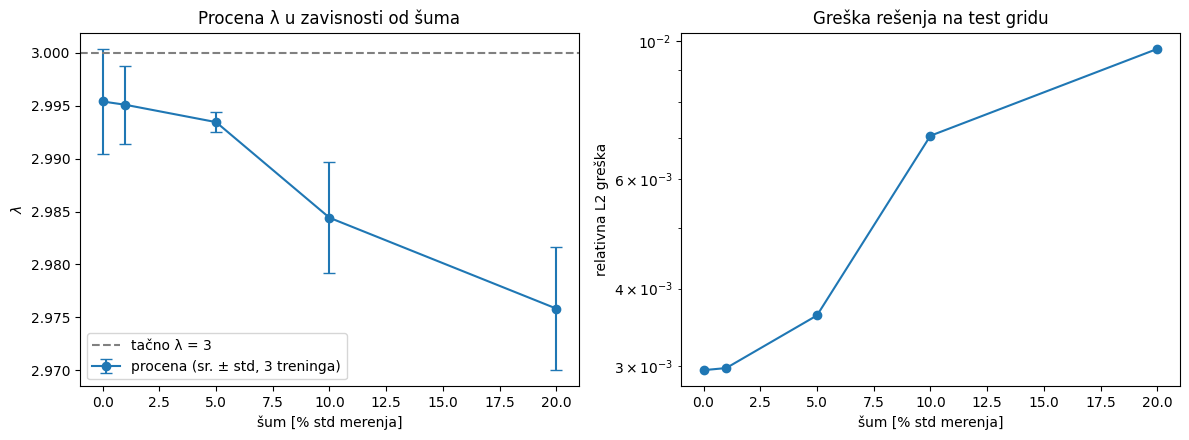

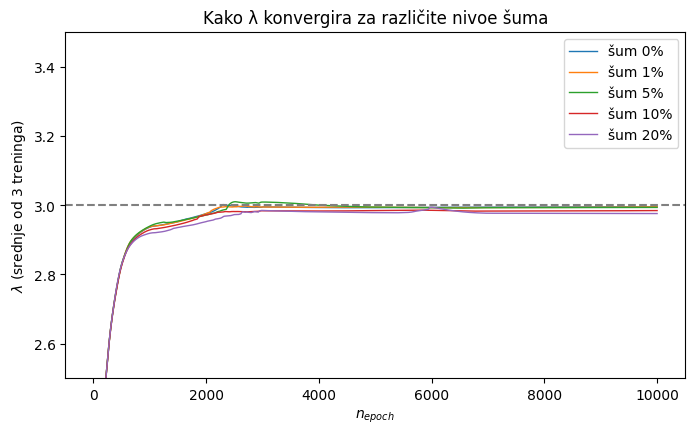

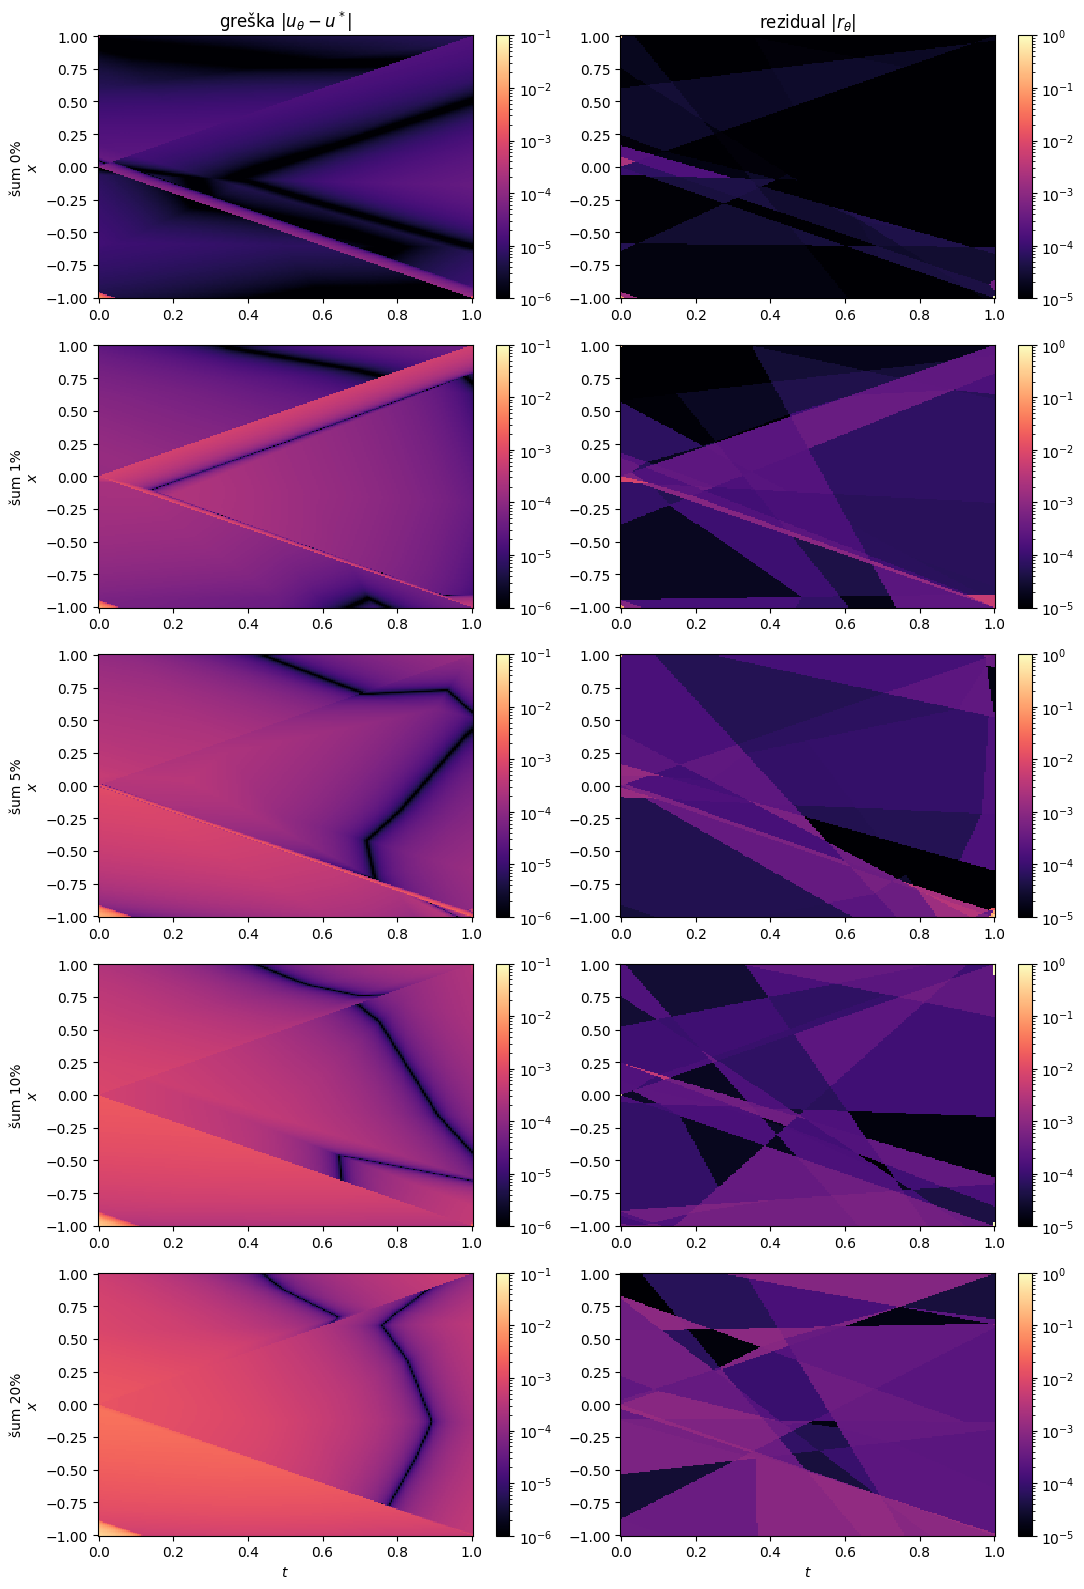

In [22]:
x = np.array(NIVOI) * 100
lam_sr  = np.array([np.mean([r['lambda'] for r in rezultati[n]]) for n in NIVOI])
lam_std = np.array([np.std([r['lambda'] for r in rezultati[n]]) for n in NIVOI])
L2_sr   = np.array([np.mean([r['rel_L2'] for r in rezultati[n]]) for n in NIVOI])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].errorbar(x, lam_sr, yerr=lam_std, fmt='o-', capsize=4, label='procena (sr. ± std, 3 treninga)')
axs[0].axhline(lambd_star, color='gray', ls='--', label='tačno λ = 3')
axs[0].set_xlabel('šum [% std merenja]'); axs[0].set_ylabel(r'$\lambda$'); axs[0].legend()
axs[0].set_title('Procena λ u zavisnosti od šuma')
axs[1].semilogy(x, L2_sr, 'o-')
axs[1].set_xlabel('šum [% std merenja]'); axs[1].set_ylabel('relativna L2 greška')
axs[1].set_title('Greška rešenja na test gridu')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for nivo in NIVOI:
    ax.plot(np.mean(putanje[nivo], axis=0), lw=1, label='šum {:.0%}'.format(nivo))
ax.axhline(lambd_star, color='gray', ls='--')
ax.set_ylim(2.5, 3.5); ax.set_xlabel('$n_{epoch}$'); ax.set_ylabel(r'$\lambda$ (srednje od 3 treninga)')
ax.legend(); ax.set_title('Kako λ konvergira za različite nivoe šuma')
plt.show()

T_, X_ = TT.numpy(), XX.numpy()
fig, axs = plt.subplots(len(NIVOI), 2, figsize=(11, 3.2 * len(NIVOI)))
for i, nivo in enumerate(NIVOI):
    r = oceni_na_gridu(modeli[nivo])
    im = axs[i, 0].pcolormesh(T_, X_, np.maximum(r['E'], 1e-7), norm=LogNorm(1e-6, 1e-1), cmap='magma', shading='auto')
    fig.colorbar(im, ax=axs[i, 0]); axs[i, 0].set_ylabel('šum {:.0%}\n$x$'.format(nivo))
    im = axs[i, 1].pcolormesh(T_, X_, np.maximum(r['R'], 1e-7), norm=LogNorm(1e-5, 1e0), cmap='magma', shading='auto')
    fig.colorbar(im, ax=axs[i, 1])
axs[0, 0].set_title(r'greška $|u_\theta - u^*|$'); axs[0, 1].set_title(r'rezidual $|r_\theta|$')
axs[-1, 0].set_xlabel('$t$'); axs[-1, 1].set_xlabel('$t$')
plt.tight_layout(); plt.show()

---
## Zaključak

- **Burgers:** PINN uhvati udarni talas kod x = 0. Adam pri tom osciluje, a L-BFGS je stabilniji i dostiže manji gubitak.
- **Eikonal:** sa Leaky ReLU aktivacijom PINN dobro reprodukuje rešenje sa oštrim grebenom.
- **Inverzni problem:** isti PINN, uz dodata merenja, iz podataka procenjuje nepoznati fizički parametar λ.